# `ngsplot`: NGSolve's `Draw`, as a matplotlib picture

`ngsolve.webgui.Draw` draws a finite element function beautifully, and then puts it inside a
browser widget you cannot script, screenshot from a script, or hand to a file.  `ngsplot.Plot`
paints the same picture -- the same colour ramp and band quantisation, the same Phong shading,
the same thick lines with their 4x MSAA, the same camera -- into an ordinary matplotlib figure,
and hands back the `AxesImage`.

Run this notebook from the first cell to the last.  What it needs:

```sh
python -m pip install -e .        # ngsplot, numpy and matplotlib
python -m pip install ngsolve     # to build the meshes there is something to draw
```

The first cell also puts `src/` of the checkout on the path, so the notebook runs from a checkout
that was never installed.  There is no widget in sight: every figure below is a figure you can
resize, retitle, put next to another one and `savefig`.

Two habits worth knowing before the first cell.  The inline backend shows every figure still
open when a cell finishes, so a cell that ends with `figure` or `pyplot.gcf()` shows its picture
twice -- once from that expression and once from the flush; the cells below therefore end with
nothing, and every plot here appears exactly once.  And the same backend hands a figure to the
browser at 72 dots per inch by default, which takes a 900x600 painting down to 400x300 by
throwing every second pixel away: the flat parts survive and a thin line comes out as a row of
dots.  The setup cell therefore asks for 144 dpi, where the painting is merely a little smaller
than it was made; a script that `savefig`s at the figure's own dpi is its own business.

In [1]:
import importlib.util
import sys
from pathlib import Path

if importlib.util.find_spec("ngsplot") is None:  # a checkout that was never installed
    for candidate in (Path.cwd() / "src", Path.cwd().parent / "src"):
        if (candidate / "ngsplot").is_dir():
            sys.path.insert(0, str(candidate))
            break

%matplotlib inline

import matplotlib
import netgen.libngpy._meshing as ngmesh
import numpy as np
import ngsolve as ngs
import ngsplot
from IPython.display import HTML
from matplotlib import animation, pyplot as mpl
from ngsplot import Plot, pyplot

mpl.rcParams["figure.dpi"] = 144  # at the inline default of 72, thin lines become dots

print(f"ngsolve {ngs.__version__}, ngsplot {ngsplot.__version__}, "
      f"matplotlib {matplotlib.__version__}")

ngsolve 6.2.2608, ngsplot 0.1.0, matplotlib 3.11.2


## 1D: a line, and a function on it

`netgen` gives no `unit_line` to Python, so the mesh is made from nodes and elements.  A dim-1
mesh is a mesh like any other, and `H1` on it behaves as it does anywhere else.

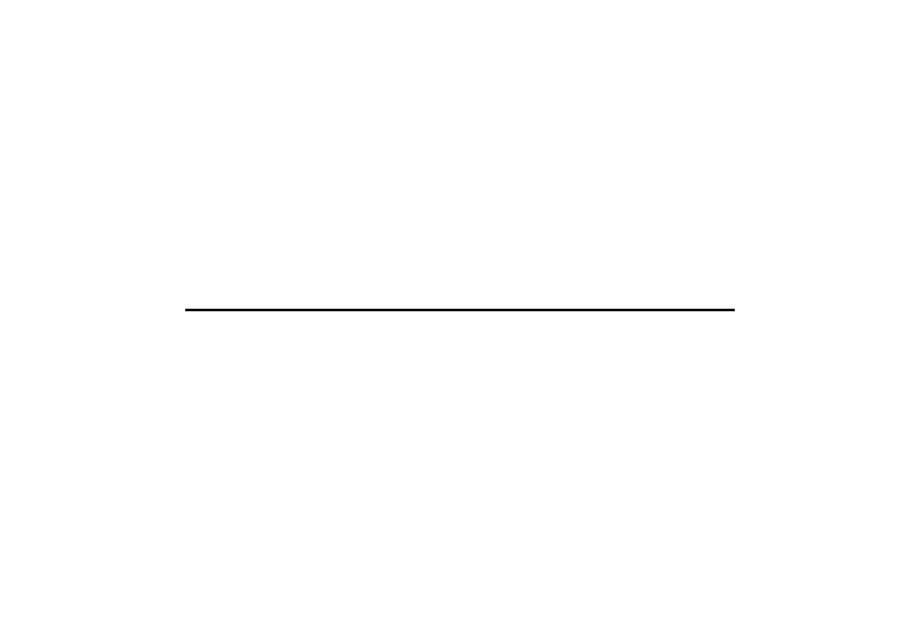

In [2]:
def line_mesh(n=40):
    """n equal segments of the unit interval, as a mesh of dimension 1."""
    mesh = ngmesh.Mesh(1)
    mesh.AddPoints(np.array([[i / n, 0.0, 0.0] for i in range(n + 1)]))
    mesh.AddElements(1, 1, np.array([[i + 1, i + 2] for i in range(n)], dtype=np.int32), base=1)
    return ngs.Mesh(mesh)


mesh1 = line_mesh(40)
u1 = ngs.GridFunction(ngs.H1(mesh1, order=3))
u1.Set(ngs.sin(2 * np.pi * ngs.x) * ngs.exp(-2 * ngs.x))

Plot(u1)

The curve comes out flat and black, which is what the page does with it.  The reason is upstream
of the painter: on a mesh of dimension 1 ngsolve sends the *geometry* of the curve and no function
values at all, so there is nothing to map a colour through.  Ask the payload and it says so in
numbers -- the value slot of every control point is zero, and the range it reports is the two
floating-point limits facing the wrong way, which is what an empty range looks like:

In [3]:
from ngsplot import _ngsolve

payload = _ngsolve.render_data(u1)
points, _ = ngsplot.geometry.edge_points(payload)
print("edges", [len(array) for array in payload["edges"]],
      "| curve points", points.shape, "| x spans", points[..., 0].min(), "to", points[..., 0].max())
print("value slot", np.unique(points[..., 3]), "| funcmin", payload["funcmin"],
      "| funcmax", payload["funcmax"])

edges [856, 856, 856] | curve points (40, 3, 4) | x spans 0.0 to 1.0
value slot [0.] | funcmin 1.7976931348623157e+308 | funcmax 2.2250738585072014e-308


So `vmin`, `vmax`, `ncolors` and `cmap` have nothing to get hold of on a line, and colouring one
would mean the painter inventing values the page was never sent -- the one place `ngsplot` will
eventually part company with the page on purpose, which `docs/SPEC.md` and the README both record
as such.  What *is* worth knowing is that none of this is about the line being straight.  A 1D
mesh may live in 2 or 3 dimensions, and then the geometry that arrives is a curve: the unit circle
below is the same one-dimensional mesh, and it draws as a circle -- and, for the same reason, in
one colour.

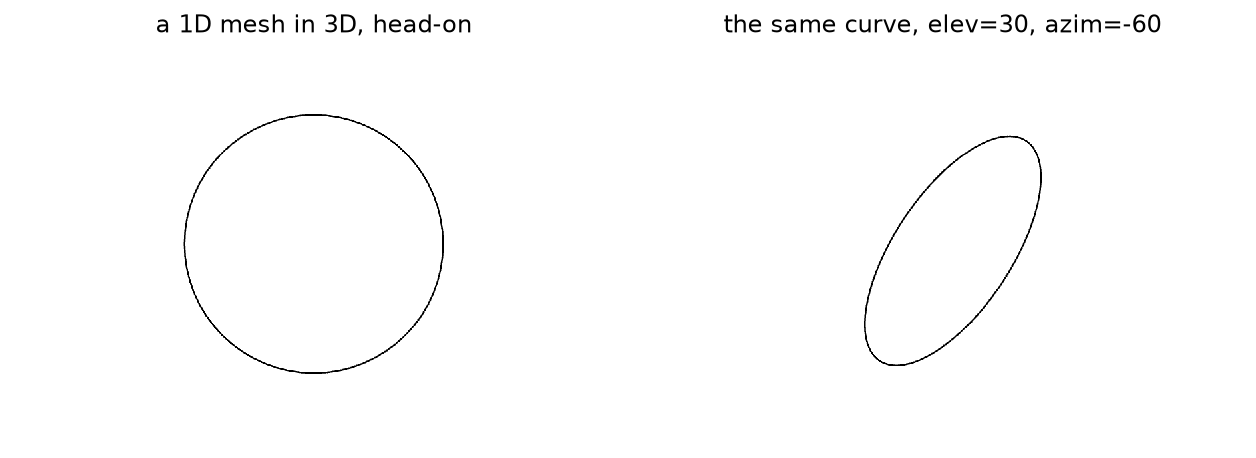

In [4]:
def circle_mesh(n=64, dim=2):
    """n segments around the unit circle, as a 1D mesh living in `dim` dimensions."""
    angles = 2 * np.pi * np.arange(n) / n
    points = np.column_stack([np.cos(angles), np.sin(angles), np.zeros(n)])[:, :dim]
    mesh = ngmesh.Mesh(dim)
    mesh.AddPoints(points)
    cells = np.array([[i + 1, i + 2 if i + 2 <= n else 1] for i in range(n)], dtype=np.int32)
    mesh.AddElements(1, 1, cells, base=1)
    return ngs.Mesh(mesh)


mcircle = circle_mesh(64, 3)
ucircle = ngs.GridFunction(ngs.H1(mcircle, order=2))
ucircle.Set(ngs.sin(4 * ngs.x * ngs.pi))

figure, axes = mpl.subplots(1, 2, figsize=(11, 4.6))

Plot(ucircle, ax=axes[0])
axes[0].set_title("a 1D mesh in 3D, head-on")

Plot(ucircle, ax=axes[1], elev=30, azim=-60)
axes[1].set_title("the same curve, elev=30, azim=-60")

figure.subplots_adjust(wspace=0.05)

## 2D: the surface case, which is what `Draw` is mostly used for

The generators are lowercase (`ngs.unit_square`, `ngs.unit_cube`), and the picture is what
`Draw(gfu)` would have put on the screen -- with a colourbar that is a real matplotlib colourbar,
in the same bands and between the same ends the panel's two number fields hold.

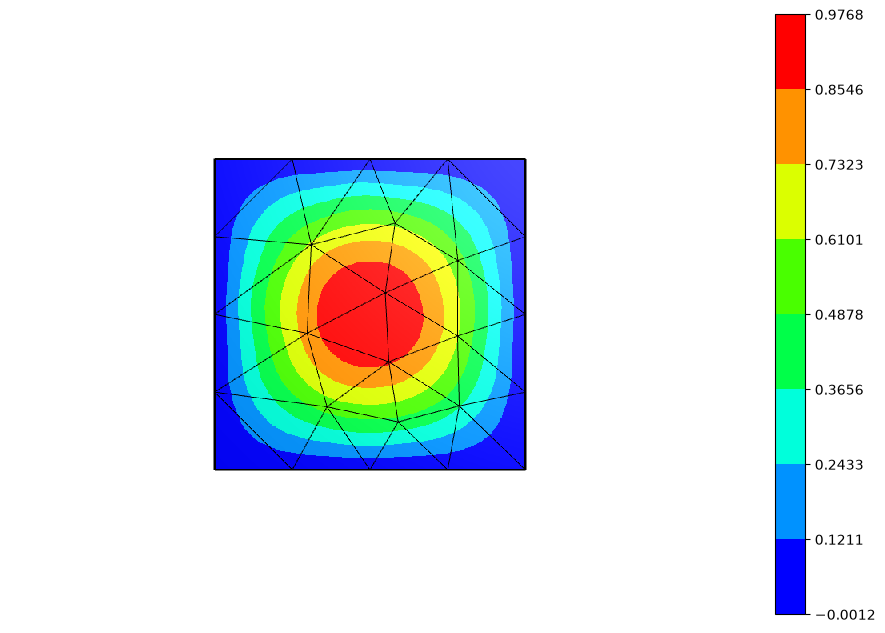

In [5]:
mesh2 = ngs.Mesh(ngs.unit_square.GenerateMesh(maxh=0.25))
u2 = ngs.GridFunction(ngs.H1(mesh2, order=3))
u2.Set(ngs.sin(np.pi * ngs.x) * ngs.sin(np.pi * ngs.y))

Plot(u2, colorbar=True)

### The knobs

Everything the panel has a control for is a keyword, and the rule for a keyword is one line
long: the ones the renderer takes (`vmin`, `vmax`, `ncolors`, `cmap`, `wireframe`, `edges`,
`line_width`, `elev`, `azim`, `roll`, `deformation`, `dark_backside`, `function_mode`, ...) go to
the painter, and the rest (`order`, `draw_vol`, `draw_surf`, `settings`, `scale`, `nodal_p1`) go
to `Draw`, which shapes the payload with them.  `eval` is the one exception: it names which part of
a value to colour (`"x"`, `"norm"`, `"real"`, `"imag"`), and it is what `Draw` *cannot* be asked
for -- see the section "Why Draw is clunky" in `docs/SPEC.md`.

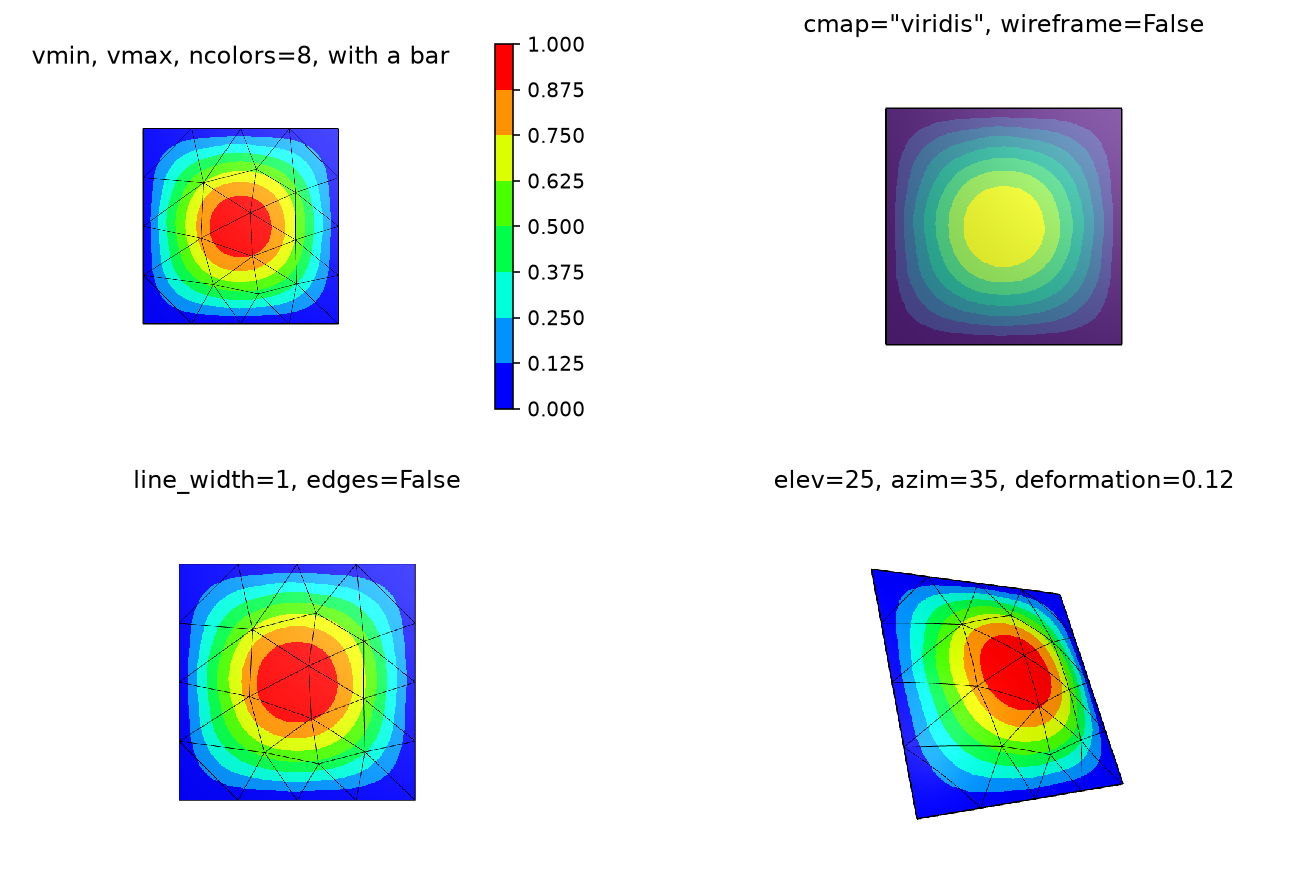

In [6]:
figure, axes = mpl.subplots(2, 2, figsize=(11.4, 7.4))

first = Plot(u2, ax=axes[0, 0], vmin=0, vmax=1, ncolors=8)
pyplot.colorbar(first)
axes[0, 0].set_title("vmin, vmax, ncolors=8, with a bar")

Plot(u2, ax=axes[0, 1], cmap="viridis", wireframe=False)
axes[0, 1].set_title('cmap="viridis", wireframe=False')

Plot(u2, ax=axes[1, 0], line_width=1, edges=False)
axes[1, 0].set_title("line_width=1, edges=False")

Plot(u2, ax=axes[1, 1], elev=25, azim=35, deformation=0.12)
axes[1, 1].set_title("elev=25, azim=35, deformation=0.12")

figure.subplots_adjust(wspace=0.25, hspace=0.25)

### What else arrives at the same picture

A `CoefficientFunction` belongs to no mesh, so it is drawn on the one you hand it -- and hears
from ngsolve, in words, when you forget to.  A `Mesh` with nothing on it is `Plot(mesh)`, or
`Plot(mesh=mesh)`, which is `Draw(mesh)`: the green of the viewer, its own shading, no scale and
so no colourbar to ask for.  A vector field is coloured by its norm unless `eval` says otherwise,
a complex one by its real part, and both are the same call.

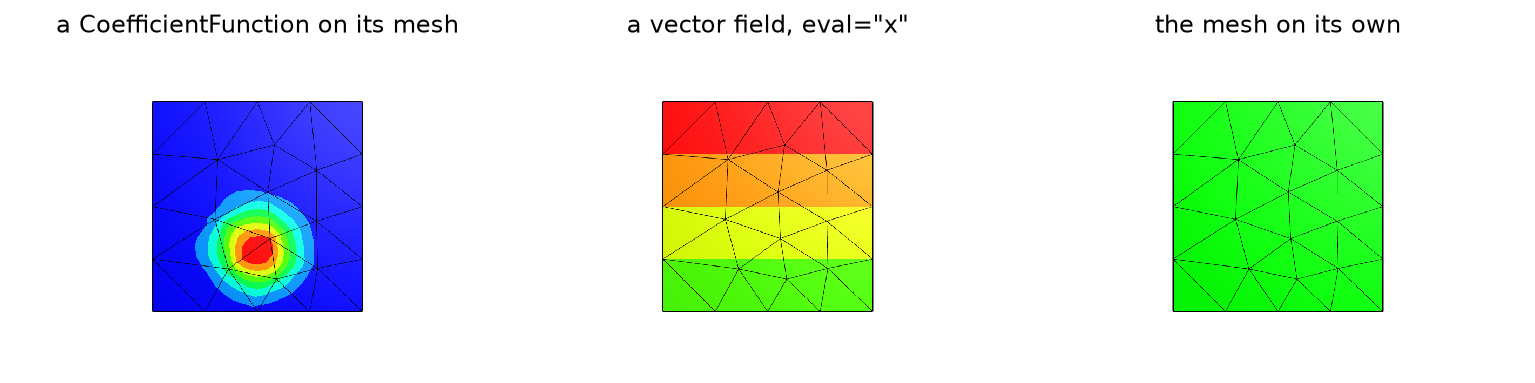

In [7]:
figure, axes = mpl.subplots(1, 3, figsize=(13.5, 4.4))

Plot(ngs.exp(-((ngs.x - 0.5) ** 2 + (ngs.y - 0.3) ** 2) * 30), ax=axes[0], mesh=mesh2)
axes[0].set_title("a CoefficientFunction on its mesh")

gfv = ngs.GridFunction(ngs.H1(mesh2, order=2, dim=2))
gfv.Set((ngs.y, -ngs.x))
Plot(gfv, ax=axes[1], eval="x")
axes[1].set_title('a vector field, eval="x"')

Plot(ax=axes[2], mesh=mesh2)
axes[2].set_title("the mesh on its own")

figure.subplots_adjust(wspace=0.05)

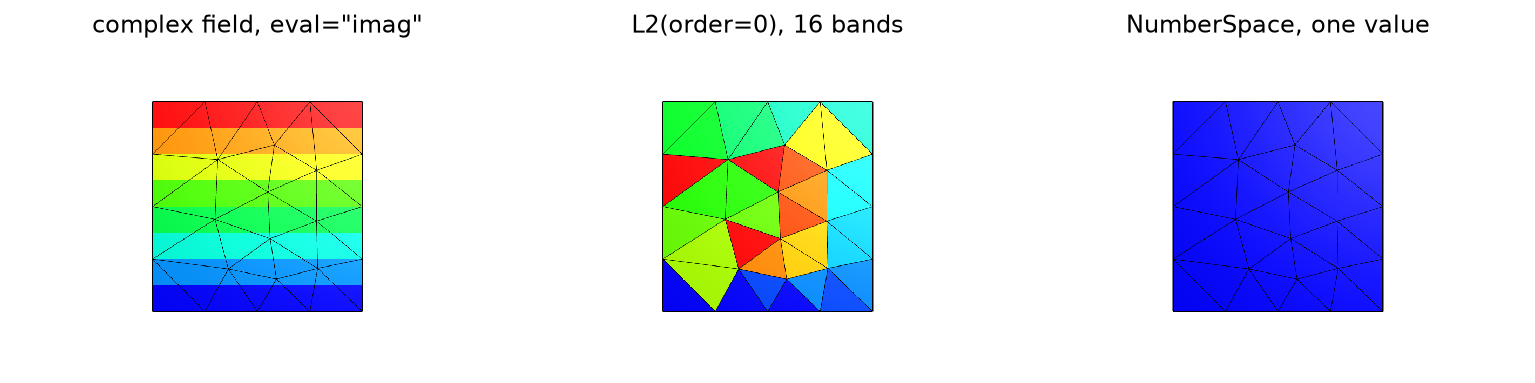

In [8]:
figure, axes = mpl.subplots(1, 3, figsize=(13.5, 4.4))

gfc = ngs.GridFunction(ngs.H1(mesh2, order=2, complex=True))
gfc.Set(ngs.x + 1j * ngs.y)
Plot(gfc, ax=axes[0], eval="imag")
axes[0].set_title('complex field, eval="imag"')

fes = ngs.L2(mesh2, order=0)  # one value per element, the piecewise-constant case
gfl = ngs.GridFunction(fes)
for i, ed in enumerate(mesh2.Elements()):
    for dof in fes.GetDofNrs(ngs.ElementId(ed)):
        gfl.vec[dof] = i
Plot(gfl, ax=axes[1], ncolors=16)
axes[1].set_title("L2(order=0), 16 bands")

Plot(ngs.GridFunction(ngs.NumberSpace(mesh2)), ax=axes[2], vmin=0, vmax=3)
axes[2].set_title("NumberSpace, one value")

figure.subplots_adjust(wspace=0.05)

## 3D: a solid

The same call: a `GridFunction` on a solid mesh arrives with `draw_vol` set by `Draw`, so the
picture is the shaded surface of the solid, seen from wherever the camera is pointed.
`dark_backside` is the knob that makes a closed solid read as closed, and `cmap="ngsolve"` is the
page's own ramp, which matplotlib has never heard of and `ngsplot` cuts to the band count asked
for without registering anything anywhere.

The point of view is spelled the way a viewer spells it: `elev`, `azim` and `roll`, in degrees --
the three angles of `Axes3D.view_init`, on a camera that stays where the page put it.  Left out,
they are the view the page opens with, straight at `xy`, which is exactly right for a flat
picture and no use at all for a solid; `elev=30, azim=-60` is the angle matplotlib's own 3D plots
open with, and what follows asks for it.  (`euler_angles` is what a panel drag leaves in a
payload's camera and what `scene.paint` still reads, so a saved page replays with the camera it was
saved with; `Plot` refuses the name so that a script has one spelling of a view, not two.)

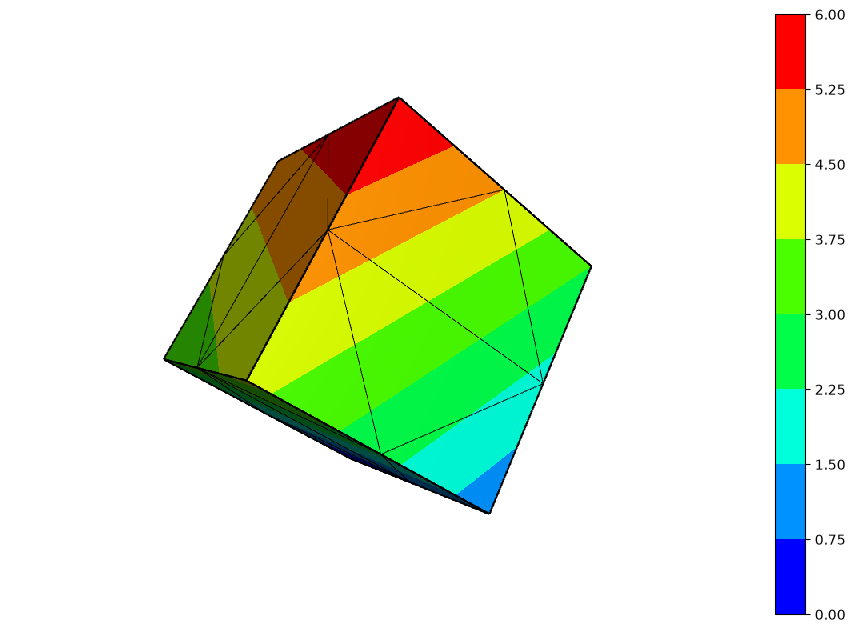

In [9]:
mesh3 = ngs.Mesh(ngs.unit_cube.GenerateMesh(maxh=0.5))
u3 = ngs.GridFunction(ngs.H1(mesh3, order=2))
u3.Set(ngs.x + 2 * ngs.y + 3 * ngs.z)

Plot(u3, elev=30, azim=-60, colorbar=True)

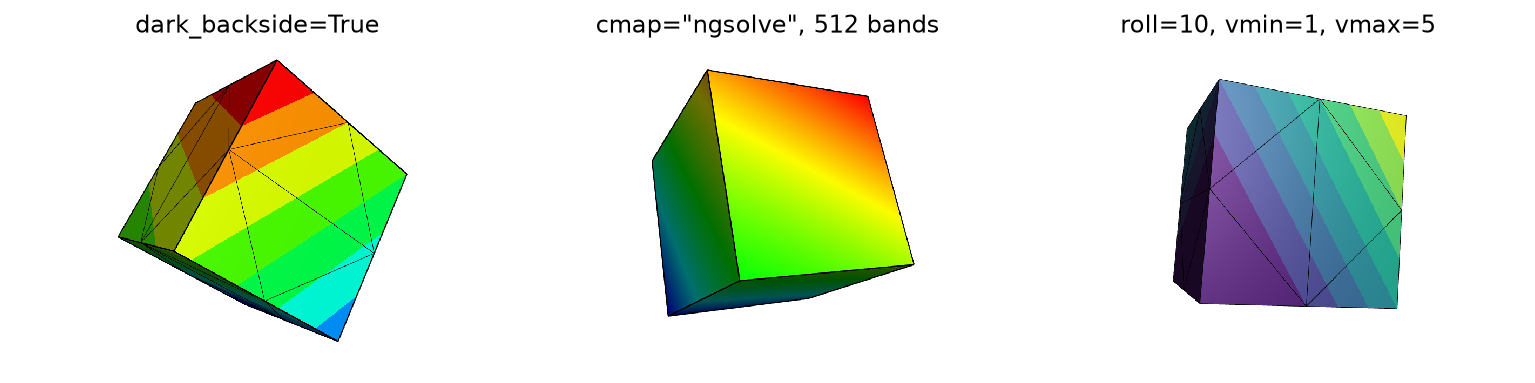

In [12]:
figure, axes = mpl.subplots(1, 3, figsize=(13.5, 4.4))

Plot(u3, ax=axes[0], elev=30, azim=-60, dark_backside=True)
axes[0].set_title("dark_backside=True")

Plot(u3, ax=axes[1], elev=20, azim=30, cmap="ngsolve", ncolors=512, wireframe=False)
axes[1].set_title('cmap="ngsolve", 512 bands')

Plot(u3, ax=axes[2], elev=-15, azim=110, roll=10, cmap="viridis", vmin=1, vmax=5, edges=False)
axes[2].set_title("roll=10, vmin=1, vmax=5")

figure.subplots_adjust(wspace=0.05)

## A time loop, animated in the notebook

Plotting twice into one axis replaces the picture instead of laying a second one under it, which
is the whole of what an animation needs: an `init` that sets the figure up and a `frame` that
redraws it, handed to `FuncAnimation`.  `to_jshtml` then embeds the frames in the notebook
itself, with matplotlib's own play, pause and scrub controls, and nothing is written to disk.

In [11]:
pyplot.close("all")  # the inline backend shows every figure still open at the end of a cell

mesh_t = ngs.Mesh(ngs.unit_square.GenerateMesh(maxh=0.2))
ut = ngs.GridFunction(ngs.H1(mesh_t, order=2))

figure, axes = mpl.subplots(figsize=(5.6, 3.8))
figure.subplots_adjust(left=0, right=1, bottom=0, top=1)  # the picture is the figure


def frame(step):
    t = step / 17
    ut.Set((1 - 0.6 * t) * ngs.sin(np.pi * (ngs.x - 0.25 * t)) * ngs.sin(np.pi * ngs.y))
    Plot(ut, ax=axes, vmin=-1, vmax=1)  # a fixed range, so that the frames are comparable


anim = animation.FuncAnimation(figure, frame, frames=range(18), init_func=lambda: None,
                               cache_frame_data=True)
html = HTML(anim.to_jshtml(fps=12, default_mode="loop"))
pyplot.close(figure)  # the widget holds the frames now; the figure has nothing left to show
html

The same loop with `pyplot.savefig` in place of `frame` is the file version of the same story:
`savefig` of the current figure comes out at the figure's own dpi, byte for byte the array the
renderer made, so twelve of them are twelve frames and ffmpeg only has to be told.

```sh
ffmpeg -framerate 12 -i frames/frame_%02d.png -pix_fmt yuv420p ngsplot.mp4
```

## From here

`help(Plot)` is the whole surface, and `from ngsplot import Plot` is the only import a script
needs; `ngsplot.pyplot` holds the rest of it (`figure`, `gcf`, `gca`, `sca`, `cla`, `close`,
`show`, `savefig`, `colorbar`).  `docs/SPEC.md` records what every pixel is doing and where in
`webgui@0.2.39` it was read from, including the two deliberate deviations from the page: no GUI
panel, and a 1D function drawn as flatly as the page draws it.